# Cycle Time & Bottleneck: Lini PCBA (data simulasi)
Notebook ini membaca hasil query SQL dan menampilkan jawaban Q1-Q14. Semua angka berasal dari `project/results/`. Jalankan `01` sampai `10` lebih dulu jika folder hasil kosong.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
R = '../2-analysis/'  # relatif terhadap results/3-presentation
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

## Q1 Kapasitas per stasiun
Bottleneck adalah stasiun dengan kapasitas terendah. Output lini = kapasitas itu.

In [2]:
q1 = pd.read_csv(R + 'q1_capacity.csv')
q1[q1['model'] == '2-layer'][['station', 'n_operator_aktif', 'ct_median_s', 'kapasitas_unit_per_hari', 'peringkat_bottleneck']]

,station,n_operator_aktif,ct_median_s,kapasitas_unit_per_hari,peringkat_bottleneck
0,Wave Soldering,4,238.20,483.60,1
1,Solder Paste Printing,4,172.60,667.30,2
2,Pick & Place,4,151.00,762.90,3
3,FCT,4,140.50,820.10,4
4,Reflow Soldering,4,140.30,821.40,5
5,THT Insertion,4,132.20,871.60,6
6,SPI (Solder Paste Inspection),4,120.50,955.60,7
7,ICT,4,118.70,970.90,8
8,AOI (Automated Optical Inspection),4,113.70,"1,012.90",9
9,Packing,4,92.30,"1,248.10",10


## Q2 Bottleneck per model dan shift
Bottleneck tidak berpindah antar model. Antar shift juga sama.

In [3]:
q2 = pd.read_csv(R + 'q2_capacity_shift.csv')
q2[q2['peringkat_bottleneck'] <= 2]

,model,shift,station,n_op,ct_median_s,kapasitas_unit_per_hari,peringkat_bottleneck
0,2-layer,A,Wave Soldering,2,239.10,240.90,1
1,2-layer,A,Solder Paste Printing,2,170.50,337.90,2
10,2-layer,B,Wave Soldering,2,237.60,242.40,1
11,2-layer,B,Solder Paste Printing,2,191.80,300.30,2
20,4-layer,A,Wave Soldering,2,252.80,227.80,1
21,4-layer,A,Solder Paste Printing,2,178.00,323.60,2
30,4-layer,B,Wave Soldering,2,253.30,227.40,1
31,4-layer,B,Solder Paste Printing,2,198.90,289.50,2
40,8-layer,A,Wave Soldering,2,279.90,205.80,1
41,8-layer,A,Solder Paste Printing,2,200.20,287.70,2


## Q3 Kestabilan kapasitas harian
Koefisien variasi (KV) kecil berarti kapasitas stabil dari hari ke hari.

In [4]:
pd.read_csv(R + 'q3_stability.csv').head(10)

,station,model,hari,rata_rata_kapasitas,simpang_baku,koef_variasi
0,Packing,2-layer,60,"1,131.70",164.50,0.14
1,AOI (Automated Optical Inspection),2-layer,60,956.80,131.90,0.14
2,SPI (Solder Paste Inspection),2-layer,60,896.70,116.00,0.13
3,FCT,2-layer,60,774.60,96.40,0.12
4,Pick & Place,2-layer,60,720.30,88.40,0.12
5,Solder Paste Printing,2-layer,60,629.70,74.10,0.12
6,ICT,2-layer,60,919.10,107.90,0.12
7,Reflow Soldering,2-layer,60,785.30,90.60,0.12
8,THT Insertion,2-layer,60,822.40,94.90,0.12
9,Wave Soldering,2-layer,60,468.40,45.20,0.10


## Q4 & Q5 Cycle time per operator dan selisih tercepat
Deviasi dihitung terhadap median stasiun-model.

In [5]:
q4 = pd.read_csv(R + 'q4_operator.csv')
print('Operator dengan deviasi > ±10%:')
q4[q4['deviasi'].abs() > 0.10][['station', 'operator_id', 'model', 'status', 'ct_median_s', 'deviasi']]

Operator dengan deviasi > ±10%:


,station,operator_id,model,status,ct_median_s,deviasi
84,Solder Paste Printing,Op_03,2-layer,baru,211.80,0.23
88,Solder Paste Printing,Op_03,4-layer,baru,221.00,0.21
92,Solder Paste Printing,Op_03,8-layer,baru,249.20,0.23
99,THT Insertion,Op_22,2-layer,reguler,107.60,-0.19
103,THT Insertion,Op_22,4-layer,reguler,120.00,-0.18
107,THT Insertion,Op_22,8-layer,reguler,134.90,-0.19


In [6]:
pd.read_csv(R + 'q5_fastest.csv').head(10)

,station,model,ct_median_stasiun,ct_tercepat,rasio_tercepat_per_median
0,THT Insertion,2-layer,132.20,107.60,0.81
1,Packing,2-layer,92.30,89.00,0.96
2,Reflow Soldering,2-layer,140.30,135.30,0.96
3,Solder Paste Printing,2-layer,172.60,166.80,0.97
4,Wave Soldering,2-layer,238.20,231.10,0.97
5,ICT,2-layer,118.70,115.50,0.97
6,Pick & Place,2-layer,151.00,147.40,0.98
7,AOI (Automated Optical Inspection),2-layer,113.70,111.30,0.98
8,SPI (Solder Paste Inspection),2-layer,120.50,118.20,0.98
9,FCT,2-layer,140.50,138.50,0.99


## Q6 Operator baru: Solder Paste Printing (Op_03)
Rasio CT per standar turun di awal, lalu mendatar di sekitar 1,2. Setelah masa belajar, operator tidak lagi membaik.

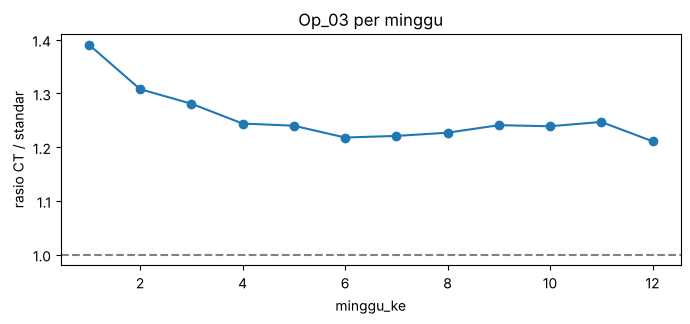

In [7]:
q6 = pd.read_csv(R + 'q6_learning.csv')
ax = q6.plot(x='minggu_ke', y='rasio_ct_per_standar', marker='o', legend=False, figsize=(8, 3))
ax.axhline(1.0, color='grey', ls='--'); ax.set_ylabel('rasio CT / standar'); ax.set_title('Op_03 per minggu')
plt.show()

## Q7 Shift dan lembur
Rasio CT per standar di hari lembur sekitar 5% lebih tinggi di kedua shift.

In [8]:
pd.read_csv(R + 'q7_shift_overtime.csv')

,shift,kondisi,baris,rasio_ct_per_standar
0,A,normal (8 jam),2788,1.00
1,A,lembur (10 jam),632,1.05
2,B,normal (8 jam),2760,1.01
3,B,lembur (10 jam),634,1.06


## Q8 Rasio CT antar model
Board 8-layer memakan waktu sekitar 17–26% lebih lama dari 2-layer.

In [9]:
pd.read_csv(R + 'q8_model_ratio.csv')

,station,ct_8layer_s,ct_2layer_s,rasio_8_per_2,rasio_4_per_2
0,SPI (Solder Paste Inspection),151.50,120.50,1.26,1.08
1,THT Insertion,166.00,132.20,1.26,1.11
2,Pick & Place,186.90,151.00,1.24,1.10
3,ICT,144.90,118.70,1.22,1.10
4,Reflow Soldering,166.20,140.30,1.19,1.07
5,FCT,166.20,140.50,1.18,1.07
6,AOI (Automated Optical Inspection),134.60,113.70,1.18,1.05
7,Wave Soldering,279.90,238.20,1.18,1.06
8,Packing,108.40,92.30,1.17,1.06
9,Solder Paste Printing,202.40,172.60,1.17,1.05


## Q9-Q11 Skenario kapasitas
Semua angka estimated. Bottleneck bisa berpindah setelah diperbaiki.

In [10]:
sc = pd.read_csv(R + 'capacity_scenarios.csv')
sc[['model', 'skenario', 'stasiun', 'output_lini_baru', 'kenaikan_output_lini', 'bottleneck_baru', 'catatan']]

,model,skenario,stasiun,output_lini_baru,kenaikan_output_lini,bottleneck_baru,catatan
0,2-layer,bottleneck CT turun 10%,Wave Soldering,537.30,0.11,Wave Soldering,estimated
1,2-layer,bottleneck CT turun 20%,Wave Soldering,604.40,0.25,Wave Soldering,estimated
2,2-layer,bottleneck CT turun 30%,Wave Soldering,667.30,0.38,Solder Paste Printing,estimated; bottleneck berpindah jika kapasitas...
3,2-layer,stasiun bukan bottleneck CT turun 30%,Solder Paste Printing,483.60,0.00,Wave Soldering,estimated; output tidak naik karena bottleneck...
4,2-layer,operator bottleneck mencapai median,Wave Soldering,490.00,0.01,Wave Soldering,estimated; operator di atas median turun ke me...
5,2-layer,operator bottleneck mencapai tercepat,Wave Soldering,498.50,0.03,Wave Soldering,estimated; semua operator setara dengan operat...
6,2-layer,operator tambahan minimal untuk target output ...,Wave Soldering,604.40,0.25,Wave Soldering,estimated; tambahan 1 operator; kapasitas stas...
7,4-layer,bottleneck CT turun 10%,Wave Soldering,505.80,0.11,Wave Soldering,estimated
8,4-layer,bottleneck CT turun 20%,Wave Soldering,569.00,0.25,Wave Soldering,estimated
9,4-layer,bottleneck CT turun 30%,Wave Soldering,632.40,0.39,Solder Paste Printing,estimated; bottleneck berpindah jika kapasitas...


## Q12 Kualitas data
Baris yang dibuang dan dampaknya terhadap angka KPI.

In [11]:
pd.read_csv('../1-data-preparation/02_cleaning_log.csv')

,langkah,tabel,status,baris,catatan
0,baris mentah daily_output,daily_output,total,7054,NaN
1,baris mentah work_hours,work_hours,total,2308,NaN
2,jam kerja lebih dari 12 jam,work_hours,dibuang,25,dibuang; output operator-hari itu ikut dibuang...
3,jam kerja nol atau negatif,work_hours,dibuang,0,NaN
4,jam kerja ganda (operator dan tanggal sama),work_hours,dibuang,0,NaN
5,operator tanpa stasiun,work_hours,dibuang,5,NaN
6,baris ganda (semua kolom sama),daily_output,dibuang,40,NaN
7,operator tidak ada di dim_operator,daily_output,dibuang,10,operator_id tidak terdaftar
8,operator tanpa stasiun,daily_output,dibuang,5,NaN
9,ok atau ng negatif,daily_output,dibuang,20,NaN


In [12]:
pd.read_csv('../1-data-preparation/02_cleaning_impact.csv')

,ukuran,sebelum_cleaning,sesudah_cleaning
0,total_ok,"484,533.00","468,920.00"
1,median_ct_wave_s,256.40,256.40
2,median_ct_spp_s,189.20,189.00
3,baris_ok_negatif,20.00,0.00


## Q13 Cocokkan dengan fakta yang ditanam
Jika semua baris DITEMUKAN, metode mendeteksi fakta yang sengaja dibuat.

In [13]:
pd.read_csv(R + 'q13_ground_truth_check.csv')

,fakta,ground_truth,temuan_analisis,status
0,bottleneck utama: Wave Soldering,Wave Soldering,Wave Soldering,DITEMUKAN
1,bottleneck kedua: Solder Paste Printing,Solder Paste Printing,Solder Paste Printing,DITEMUKAN
2,operator lambat Op_03 di SPP: deviasi terbesar...,+25% (steady),deviasi rata-rata +22.4%; terbesar di 3 dari 3...,DITEMUKAN
3,operator cepat Op_22 di THT: deviasi terkecil ...,−20%,deviasi rata-rata -18.5%; terkecil di 3 dari 3...,DITEMUKAN
4,lembur ±5% lebih lambat dari normal (kedua shift),+5%,A +4.8%; B +5.2%,DITEMUKAN
5,data kotor: jam kerja > 12 jam,25,25,DITEMUKAN
6,data kotor: ok negatif,20,20,DITEMUKAN
7,data kotor: baris ganda,40,40,DITEMUKAN
8,data kotor: operator tidak terdaftar (Op_99),10,10,DITEMUKAN
9,data kotor: jam kerja hilang → output tanpa ja...,90,90,DITEMUKAN


## Q14 Cek silang SQL, pandas, dan Excel

In [14]:
pd.read_csv(R + '04_crosscheck_sql_pandas.csv')

,cek,jumlah_nilai,selisih_maks,toleransi,status
0,CT median per operator (q4) vs pandas,120,0.00,0.05,PASS
1,kapasitas stasiun-model (q1) vs pandas,30,0.05,0.05,PASS
2,rasio CT per standar shift x lembur (q7) vs pa...,4,0.00,0.00,PASS


In [15]:
pd.read_csv(R + '05_crosscheck_spreadsheet.csv')

,station,operator_id,model,ct_excel_s,ct_sql_s,selisih_s,status
0,Solder Paste Printing,Op_03,2-layer,215.69,215.69,0,PASS
1,Solder Paste Printing,Op_03,4-layer,225.02,225.02,0,PASS
2,Solder Paste Printing,Op_03,8-layer,251.98,251.98,0,PASS
3,THT Insertion,Op_22,2-layer,108.27,108.27,0,PASS
4,THT Insertion,Op_24,4-layer,150.44,150.44,0,PASS
5,AOI (Automated Optical Inspection),Op_18,4-layer,119.10,119.10,0,PASS
6,THT Insertion,Op_21,4-layer,146.00,146.00,0,PASS
7,Solder Paste Printing,Op_04,2-layer,168.33,168.33,0,PASS
8,Reflow Soldering,Op_15,4-layer,151.49,151.49,0,PASS
9,FCT,Op_33,8-layer,169.58,169.58,0,PASS
